# TDDA Tutorial Using EM-DAT Data

In [20]:
# Mount drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [21]:
import pandas as pd

# Directly load the EM-DAT excel file from Google Drive
file_path = '/content/drive/MyDrive/Open Data/EMDAT/data_emdat_2000_2025_world.xlsx'
df = pd.read_excel(file_path)
display(df.head())

,DisNo.,Historic,Classification Key,Disaster Group,Disaster Subgroup,Disaster Type,Disaster Subtype,External IDs,Event Name,ISO,...,"Reconstruction Costs, Adjusted ('000 US$)",Insured Damage ('000 US$),"Insured Damage, Adjusted ('000 US$)",Total Damage ('000 US$),"Total Damage, Adjusted ('000 US$)",CPI,Admin Units,GADM Admin Units,Entry Date,Last Update
0,2025-0303-ECU,No,nat-geo-ear-gro,Natural,Geophysical,Earthquake,Ground movement,NaN,NaN,ECU,...,NaN,NaN,NaN,NaN,NaN,100.0,NaN,NaN,2025-04-28,2026-05-15
1,2025-0750-AFG,No,nat-geo-ear-gro,Natural,Geophysical,Earthquake,Ground movement,GLIDE:EQ-2025-000153,NaN,AFG,...,NaN,NaN,NaN,180000.0,180000.0,100.0,NaN,NaN,2025-09-01,2026-05-15
2,2024-0962-AGO,No,nat-bio-epi-bac,Natural,Biological,Epidemic,Bacterial disease,GLIDE:EP-2025-000013,Cholera,AGO,...,NaN,NaN,NaN,NaN,NaN,100.0,NaN,NaN,2025-01-17,2026-05-15
3,2025-9122-SOM,No,nat-cli-dro-dro,Natural,Climatological,Drought,Drought,NaN,NaN,SOM,...,NaN,NaN,NaN,NaN,NaN,100.0,NaN,NaN,2025-02-26,2026-05-15
4,2025-0272-KGZ,No,nat-bio-epi-vir,Natural,Biological,Epidemic,Viral disease,GLIDE:EP-2025-000030|GLIDE:EP-2025-000105,Measles & Rubella,KGZ,...,NaN,NaN,NaN,NaN,NaN,100.0,NaN,NaN,2025-04-16,2026-05-20


In [22]:
# Detailed DataFrame summary
print("--- Info Summary ---")
df.info()

--- Info Summary ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10746 entries, 0 to 10745
Data columns (total 47 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   DisNo.                                     10746 non-null  object 
 1   Historic                                   10746 non-null  object 
 2   Classification Key                         10746 non-null  object 
 3   Disaster Group                             10746 non-null  object 
 4   Disaster Subgroup                          10746 non-null  object 
 5   Disaster Type                              10746 non-null  object 
 6   Disaster Subtype                           10746 non-null  object 
 7   External IDs                               4280 non-null   object 
 8   Event Name                                 2675 non-null   object 
 9   ISO                                        10746 non-null  object 
 10  C

In [27]:
# Filter for natural climatological disasters in Europe
df_met_eu = df[
    (df['Disaster Group'] == 'Natural') &
    (df['Disaster Subgroup'] == 'Meteorological') &
    (df['Region'] == 'Europe')
]

# Display the filtered dataframe
display(df_met_eu.head())
print(f"Total disasters found: {len(df_met_eu)}")

,DisNo.,Historic,Classification Key,Disaster Group,Disaster Subgroup,Disaster Type,Disaster Subtype,External IDs,Event Name,ISO,...,"Reconstruction Costs, Adjusted ('000 US$)",Insured Damage ('000 US$),"Insured Damage, Adjusted ('000 US$)",Total Damage ('000 US$),"Total Damage, Adjusted ('000 US$)",CPI,Admin Units,GADM Admin Units,Entry Date,Last Update
15,2022-0465-LIE,No,nat-met-ext-hea,Natural,Meteorological,Extreme temperature,Heat wave,GLIDE:HT-2022-000399,NaN,LIE,...,NaN,NaN,NaN,NaN,NaN,90.902697,NaN,NaN,2026-08-11,2026-08-11
66,2000-0576-RUS,No,nat-met-sto-tro,Natural,Meteorological,Storm,Tropical cyclone,NaN,Typhoon 'Saomai' (Osang),RUS,...,NaN,NaN,NaN,50.0,93.0,53.487737,"[{""adm1_code"":2516,""adm1_name"":""Khabarovskiy K...","[{""gid_1"":""RUS.28_1"",""migration_date"":""2025-12...",2007-04-18,2026-08-20
71,2000-0714-DEU,No,nat-met-sto-sev,Natural,Meteorological,Storm,Severe weather,HANZE:20231|HANZE:21263,Storm 'Oratia' (Tora),DEU,...,NaN,NaN,NaN,NaN,NaN,53.487737,NaN,NaN,2026-08-19,2026-08-19
72,2000-0714-FRA,No,nat-met-sto-sev,Natural,Meteorological,Storm,Severe weather,HANZE:20231|HANZE:21263,Storm 'Oratia' (Tora),FRA,...,NaN,NaN,NaN,NaN,NaN,53.487737,NaN,NaN,2026-08-19,2026-08-19
73,2000-0714-GBR,No,nat-met-sto-sev,Natural,Meteorological,Storm,Severe weather,HANZE:20231|HANZE:21263,Storm 'Oratia' (Tora),GBR,...,NaN,1100000.0,2056546.0,1500000.0,2804381.0,53.487737,"[{""adm2_code"":40107,""adm2_name"":""East Sussex""}...","[{""gid_2"":""GBR.1.105_1"",""migration_date"":""2025...",2008-04-08,2026-08-19


Total disasters found: 732


In [28]:
# Calculate the count of disasters per year
disasters_per_year = df_met_eu.groupby('Start Year').size().reset_index(name='Climate Count')
display(disasters_per_year)

,Start Year,Climate Count
0,2000,25
1,2001,14
2,2002,25
3,2003,22
4,2004,17
5,2005,45
6,2006,25
7,2007,35
8,2008,14
9,2009,27


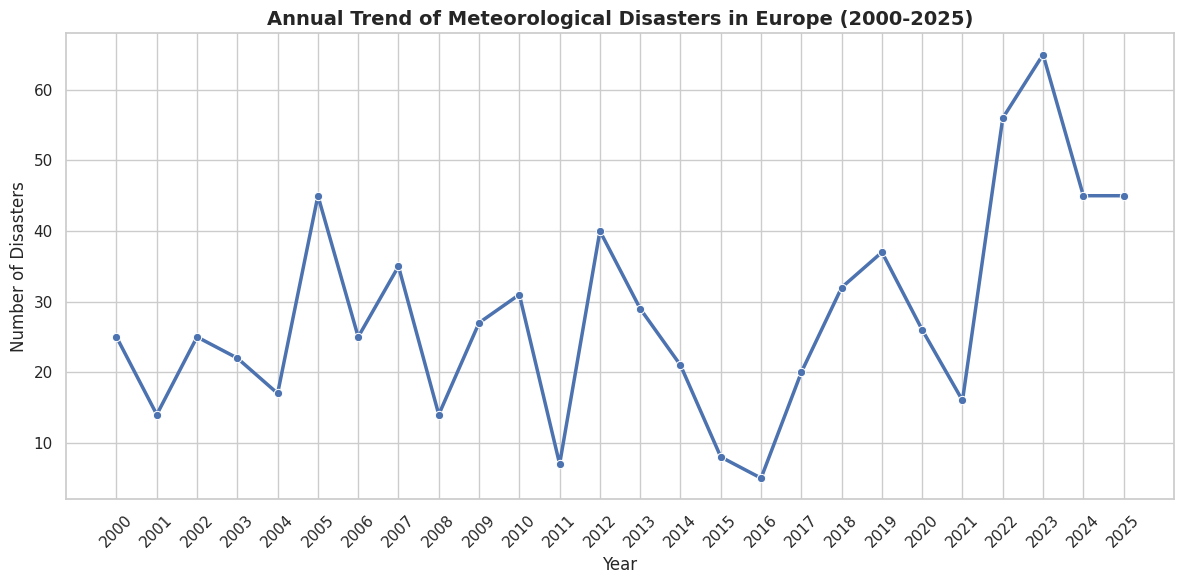

In [29]:
import seaborn as sns
import matplotlib.pyplot as plt

# Set the aesthetic style of the plot
sns.set_theme(style="whitegrid")

# Create the line plot
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=disasters_per_year,
    x='Start Year',
    y='Count',
    marker='o',
    color='b',
    linewidth=2.5
)

# Add titles and labels
plt.title('Annual Trend of Meteorological Disasters in Europe (2000-2025)', fontsize=14, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('Number of Disasters', fontsize=12)
plt.xticks(disasters_per_year['Start Year'], rotation=45)

# Show the plot
plt.tight_layout()
plt.show()

In [30]:
# Filter the dataset for only 'Heat wave' disasters
df_heatwaves = df_met_eu[df_met_eu['Disaster Subtype'] == 'Heat wave']

# Display the first few rows of the filtered dataset
display(df_heatwaves.head())
print(f"Total heat waves found: {len(df_heatwaves)}")

,DisNo.,Historic,Classification Key,Disaster Group,Disaster Subgroup,Disaster Type,Disaster Subtype,External IDs,Event Name,ISO,...,"Reconstruction Costs, Adjusted ('000 US$)",Insured Damage ('000 US$),"Insured Damage, Adjusted ('000 US$)",Total Damage ('000 US$),"Total Damage, Adjusted ('000 US$)",CPI,Admin Units,GADM Admin Units,Entry Date,Last Update
15,2022-0465-LIE,No,nat-met-ext-hea,Natural,Meteorological,Extreme temperature,Heat wave,GLIDE:HT-2022-000399,NaN,LIE,...,NaN,NaN,NaN,NaN,NaN,90.902697,NaN,NaN,2026-08-11,2026-08-11
106,2025-0462-BGR,No,nat-met-ext-hea,Natural,Meteorological,Extreme temperature,Heat wave,NaN,NaN,BGR,...,NaN,NaN,NaN,NaN,NaN,100.000000,NaN,NaN,2026-08-05,2026-08-28
107,2025-0462-ITA,No,nat-met-ext-hea,Natural,Meteorological,Extreme temperature,Heat wave,NaN,NaN,ITA,...,NaN,NaN,NaN,NaN,NaN,100.000000,NaN,NaN,2025-07-04,2026-08-28
108,2025-0462-MKD,No,nat-met-ext-hea,Natural,Meteorological,Extreme temperature,Heat wave,NaN,NaN,MKD,...,NaN,NaN,NaN,NaN,NaN,100.000000,NaN,NaN,2026-08-05,2026-08-28
109,2025-0462-SVK,No,nat-met-ext-hea,Natural,Meteorological,Extreme temperature,Heat wave,NaN,NaN,SVK,...,NaN,NaN,NaN,NaN,NaN,100.000000,NaN,NaN,2026-08-05,2026-08-28


Total heat waves found: 206


AttributeError: Rectangle.set() got an unexpected keyword argument 'marker'

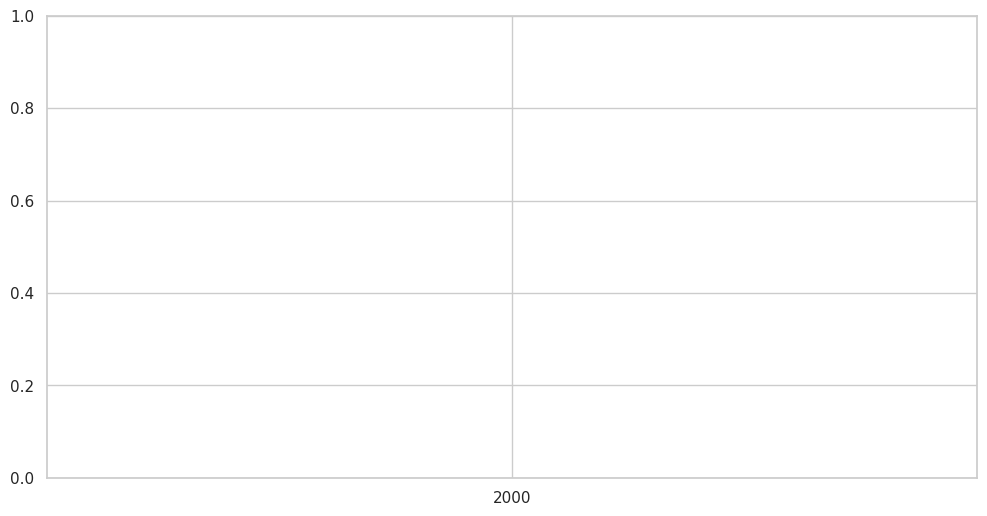

In [33]:
# Calculate the number of heat waves per year
heatwaves_per_year = df_heatwaves.groupby('Start Year').size().reset_index(name='Heatwave Count')

# Calculate mean and standard deviation
mean_val = heatwaves_per_year['Heatwave Count'].mean()
std_val = heatwaves_per_year['Heatwave Count'].std()

# Create the line plot using Seaborn
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=heatwaves_per_year,
    x='Start Year',
    y='Heatwave Count',
    marker='s',
    color='red',
    linewidth=2.5,
    label='Heat Waves'
)

# Add horizontal lines for Average and Standard Deviation thresholds
plt.axhline(mean_val, color='blue', linestyle='--', linewidth=1.5, label=f'Average ({mean_val:.1f})')
plt.axhline(mean_val + std_val, color='green', linestyle=':', linewidth=1.5, label=f'+1 Std Dev ({mean_val + std_val:.1f})')
plt.axhline(max(0, mean_val - std_val), color='green', linestyle=':', linewidth=1.5, label=f'-1 Std Dev ({max(0, mean_val - std_val):.1f})')

# Set labels and title
plt.title('Annual Trend of Heat Wave Disasters in Europe (2000-2025)', fontsize=14, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('Number of Heat Waves', fontsize=12)
plt.xticks(heatwaves_per_year['Start Year'], rotation=45)
plt.legend(loc='upper left')

# Show the visualization
plt.tight_layout()
plt.show()

## 1. Handling New Data Sources Validation
Checklist: https://book.tdda.info/book/checklists.html#NDS

## 2. Data Validation (DV)
Checklist: https://book.tdda.info/book/checklists.html#DV